<a href="https://colab.research.google.com/github/mjmujeeb/AI-Driven-Digital-Twin-for-Predictive-Maintenance-for-Industry-4.0/blob/main/predictive_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

import warnings
warnings.filterwarnings('ignore')

In [ ]:
df = pd.read_csv('/content/train_FD001.txt', sep='\s+', header=None)

In [ ]:
columns = ['engine_id', 'cycle'] + \
          [f'op_setting_{i}' for i in range(1,4)] + \
          [f'sensor_{i}' for i in range(1,22)]

df.columns = columns

In [ ]:
print("Dataset Shape:", df.shape)

Dataset Shape: (20631, 26)


In [ ]:
print("\nFirst 5 rows:")
print(df.head())



First 5 rows:
   engine_id  cycle  op_setting_1  op_setting_2  op_setting_3  sensor_1  \
0          1      1       -0.0007       -0.0004         100.0    518.67   
1          1      2        0.0019       -0.0003         100.0    518.67   
2          1      3       -0.0043        0.0003         100.0    518.67   
3          1      4        0.0007        0.0000         100.0    518.67   
4          1      5       -0.0019       -0.0002         100.0    518.67   

   sensor_2  sensor_3  sensor_4  sensor_5  ...  sensor_12  sensor_13  \
0    641.82   1589.70   1400.60     14.62  ...     521.66    2388.02   
1    642.15   1591.82   1403.14     14.62  ...     522.28    2388.07   
2    642.35   1587.99   1404.20     14.62  ...     522.42    2388.03   
3    642.35   1582.79   1401.87     14.62  ...     522.86    2388.08   
4    642.37   1582.85   1406.22     14.62  ...     522.19    2388.04   

   sensor_14  sensor_15  sensor_16  sensor_17  sensor_18  sensor_19  \
0    8138.62     8.4195       

In [ ]:
print("\nMissing Values:")
print(df.isnull().sum())


Missing Values:
engine_id       0
cycle           0
op_setting_1    0
op_setting_2    0
op_setting_3    0
sensor_1        0
sensor_2        0
sensor_3        0
sensor_4        0
sensor_5        0
sensor_6        0
sensor_7        0
sensor_8        0
sensor_9        0
sensor_10       0
sensor_11       0
sensor_12       0
sensor_13       0
sensor_14       0
sensor_15       0
sensor_16       0
sensor_17       0
sensor_18       0
sensor_19       0
sensor_20       0
sensor_21       0
dtype: int64


In [ ]:
# Remove rows with missing values
df = df.dropna()

# Check again
print("Missing values after cleaning:")
print(df.isnull().sum())

print("\nNew shape:", df.shape)

Missing values after cleaning:
engine_id       0
cycle           0
op_setting_1    0
op_setting_2    0
op_setting_3    0
sensor_1        0
sensor_2        0
sensor_3        0
sensor_4        0
sensor_5        0
sensor_6        0
sensor_7        0
sensor_8        0
sensor_9        0
sensor_10       0
sensor_11       0
sensor_12       0
sensor_13       0
sensor_14       0
sensor_15       0
sensor_16       0
sensor_17       0
sensor_18       0
sensor_19       0
sensor_20       0
sensor_21       0
dtype: int64

New shape: (20631, 26)


In [ ]:
# STEP 2: Create RUL

# Get maximum cycle for each engine
rul = df.groupby('engine_id')['cycle'].max().reset_index()
rul.columns = ['engine_id', 'max_cycle']

# Merge with original dataset
df = df.merge(rul, on='engine_id')

# Calculate Remaining Useful Life
df['RUL'] = df['max_cycle'] - df['cycle']

# Check result
df[['engine_id','cycle','max_cycle','RUL']].head(10)

,engine_id,cycle,max_cycle,RUL
0,1,1,192,191
1,1,2,192,190
2,1,3,192,189
3,1,4,192,188
4,1,5,192,187
5,1,6,192,186
6,1,7,192,185
7,1,8,192,184
8,1,9,192,183
9,1,10,192,182


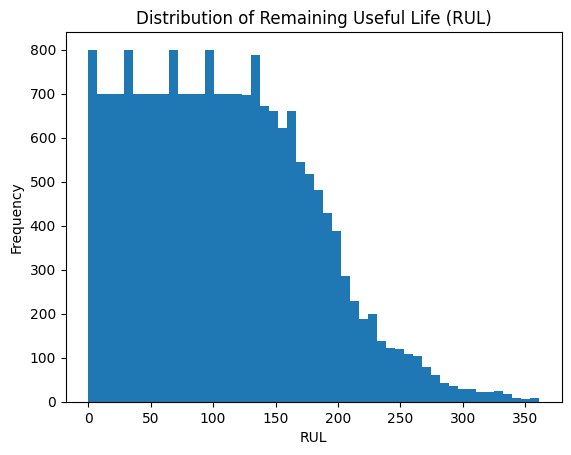

In [ ]:
import matplotlib.pyplot as plt

plt.figure()
plt.hist(df['RUL'], bins=50)
plt.title("Distribution of Remaining Useful Life (RUL)")
plt.xlabel("RUL")
plt.ylabel("Frequency")
plt.show()

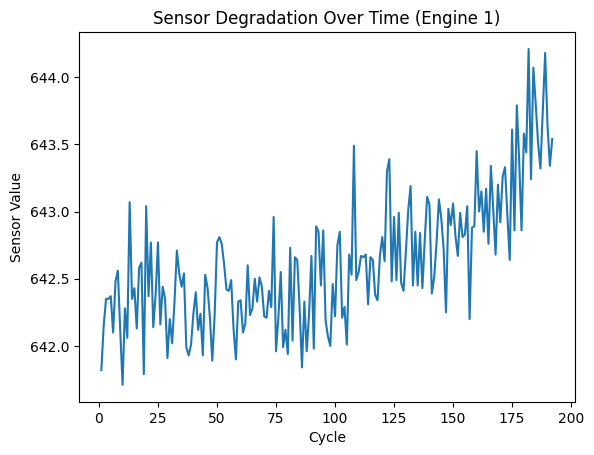

In [ ]:
engine_1 = df[df['engine_id'] == 1]

plt.figure()
plt.plot(engine_1['cycle'], engine_1['sensor_2'])
plt.title("Sensor Degradation Over Time (Engine 1)")
plt.xlabel("Cycle")
plt.ylabel("Sensor Value")
plt.show()

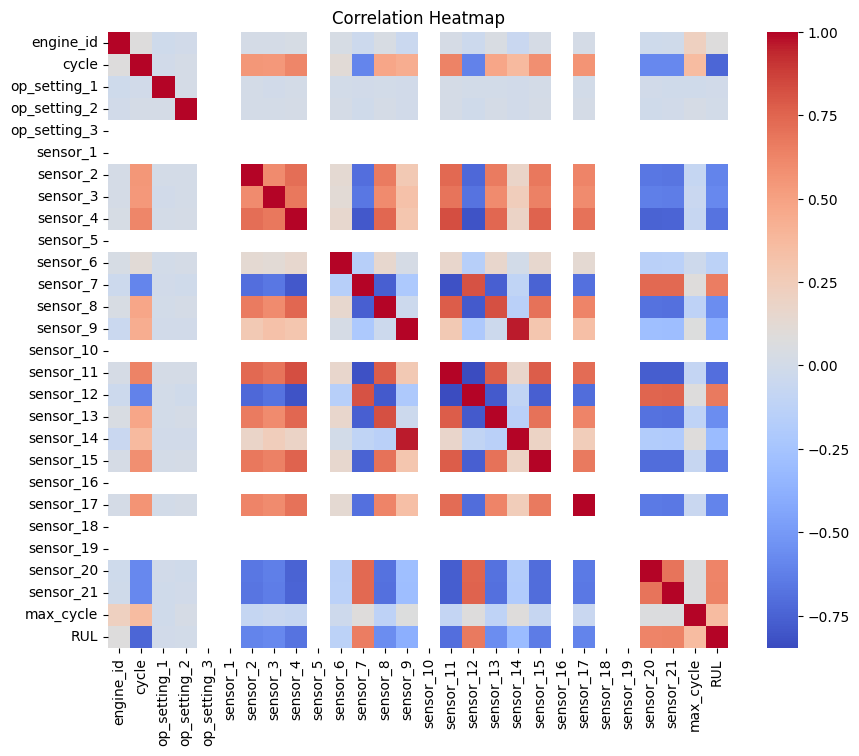

In [ ]:
import seaborn as sns

plt.figure(figsize=(10,8))
sns.heatmap(df.corr(), cmap='coolwarm')
plt.title("Correlation Heatmap")
plt.show()

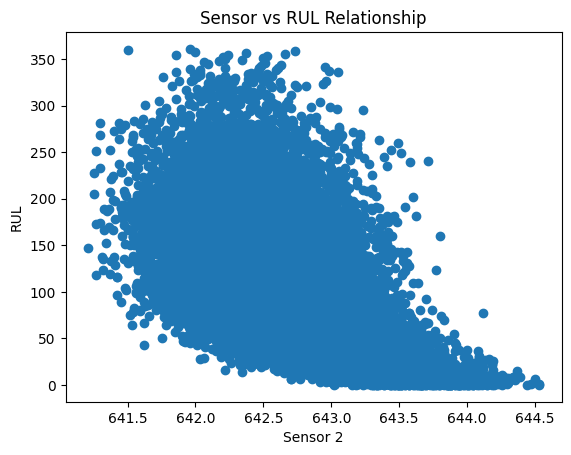

In [ ]:
plt.figure()
plt.scatter(df['sensor_2'], df['RUL'])
plt.xlabel("Sensor 2")
plt.ylabel("RUL")
plt.title("Sensor vs RUL Relationship")
plt.show()

In [ ]:
# Check variance of each column
variance = df.var()

# Keep only columns with variance > threshold
low_variance_cols = variance[variance < 0.01].index

print("Low variance columns:", low_variance_cols)




Low variance columns: Index(['op_setting_1', 'op_setting_2', 'op_setting_3', 'sensor_1', 'sensor_5',
       'sensor_6', 'sensor_8', 'sensor_10', 'sensor_13', 'sensor_15',
       'sensor_16', 'sensor_18', 'sensor_19'],
      dtype='object')


In [ ]:
for col in ['op_setting_1', 'op_setting_2', 'op_setting_3', 'sensor_1', 'sensor_5',
       'sensor_6', 'sensor_8', 'sensor_10', 'sensor_13', 'sensor_15',
       'sensor_16', 'sensor_18', 'sensor_19']:
    print(col, "unique values:", df[col].nunique())

op_setting_1 unique values: 158
op_setting_2 unique values: 13
op_setting_3 unique values: 1
sensor_1 unique values: 1
sensor_5 unique values: 1
sensor_6 unique values: 2
sensor_8 unique values: 53
sensor_10 unique values: 1
sensor_13 unique values: 56
sensor_15 unique values: 1918
sensor_16 unique values: 1
sensor_18 unique values: 1
sensor_19 unique values: 1


In [ ]:
drop_cols = ['sensor_1','sensor_5','sensor_6','sensor_10','sensor_16','sensor_18','sensor_19']
df = df.drop(columns=drop_cols)
print(df)

       engine_id  cycle  op_setting_1  op_setting_2  op_setting_3  sensor_2  \
0              1      1       -0.0007       -0.0004         100.0    641.82   
1              1      2        0.0019       -0.0003         100.0    642.15   
2              1      3       -0.0043        0.0003         100.0    642.35   
3              1      4        0.0007        0.0000         100.0    642.35   
4              1      5       -0.0019       -0.0002         100.0    642.37   
...          ...    ...           ...           ...           ...       ...   
20626        100    196       -0.0004       -0.0003         100.0    643.49   
20627        100    197       -0.0016       -0.0005         100.0    643.54   
20628        100    198        0.0004        0.0000         100.0    643.42   
20629        100    199       -0.0011        0.0003         100.0    643.23   
20630        100    200       -0.0032       -0.0005         100.0    643.85   

       sensor_3  sensor_4  sensor_7  sensor_8  ... 

In [ ]:
# Remove non-useful columns
df = df.drop(columns=['engine_id','cycle','max_cycle'])

# Define input and output
X = df.drop(columns=['RUL'])
y = df['RUL']

In [ ]:
# Updated RUL classification (better separation)

def classify_rul(rul):
    if rul > 100:
        return 0
    elif rul > 50:
        return 1
    else:
        return 2  # Critical

y_class = y.apply(classify_rul)

print(y_class.value_counts())

RUL
0    10531
2     5100
1     5000
Name: count, dtype: int64


In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y_class, test_size=0.2, random_state=42
)

Decision Tree Accuracy: 0.6954204022292222

Classification Report:
               precision    recall  f1-score   support

           0       0.79      0.76      0.77      2176
           1       0.41      0.45      0.43       967
           2       0.80      0.81      0.80       984

    accuracy                           0.70      4127
   macro avg       0.67      0.67      0.67      4127
weighted avg       0.70      0.70      0.70      4127



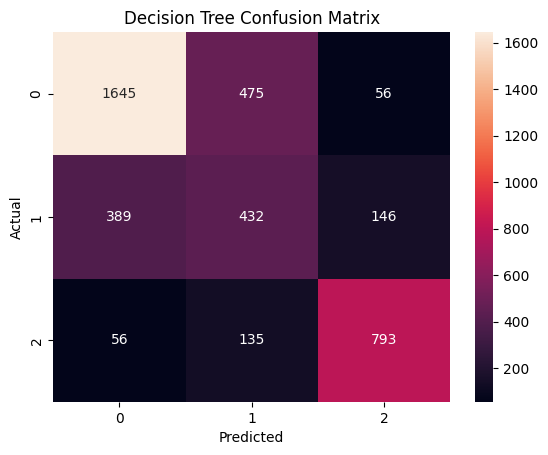

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

# Train model
dt = DecisionTreeClassifier(random_state=42)

dt.fit(X_train, y_train)

# Predictions
y_pred_dt = dt.predict(X_test)

# Accuracy
print("Decision Tree Accuracy:", accuracy_score(y_test, y_pred_dt))

# Classification Report
print("\nClassification Report:\n", classification_report(y_test, y_pred_dt))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred_dt)

plt.figure()
sns.heatmap(cm, annot=True, fmt='d')
plt.title("Decision Tree Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

Random Forest Accuracy: 0.7879815846862127

Classification Report:
               precision    recall  f1-score   support

           0       0.80      0.92      0.86      2176
           1       0.60      0.45      0.52       967
           2       0.91      0.83      0.87       984

    accuracy                           0.79      4127
   macro avg       0.77      0.73      0.75      4127
weighted avg       0.78      0.79      0.78      4127



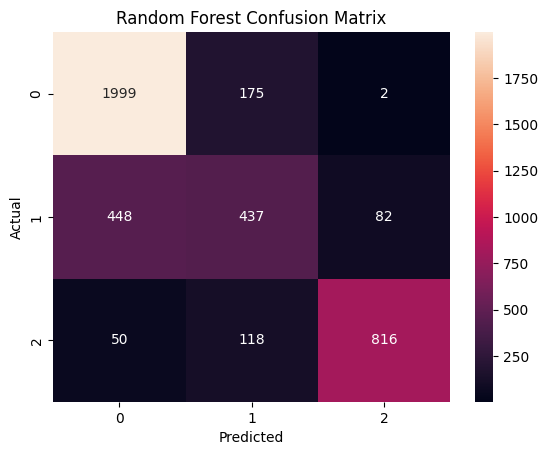

In [ ]:
from sklearn.ensemble import RandomForestClassifier

# Train model
rf = RandomForestClassifier(n_estimators=200, random_state=42)

rf.fit(X_train, y_train)

# Predictions
y_pred_rf = rf.predict(X_test)

# Accuracy
print("Random Forest Accuracy:", accuracy_score(y_test, y_pred_rf))

# Classification Report
print("\nClassification Report:\n", classification_report(y_test, y_pred_rf))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred_rf)

plt.figure()
sns.heatmap(cm, annot=True, fmt='d')
plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

XGBoost Accuracy: 0.7860431306033439

Classification Report:
               precision    recall  f1-score   support

           0       0.80      0.91      0.85      2176
           1       0.59      0.46      0.51       967
           2       0.91      0.83      0.87       984

    accuracy                           0.79      4127
   macro avg       0.77      0.73      0.75      4127
weighted avg       0.78      0.79      0.78      4127



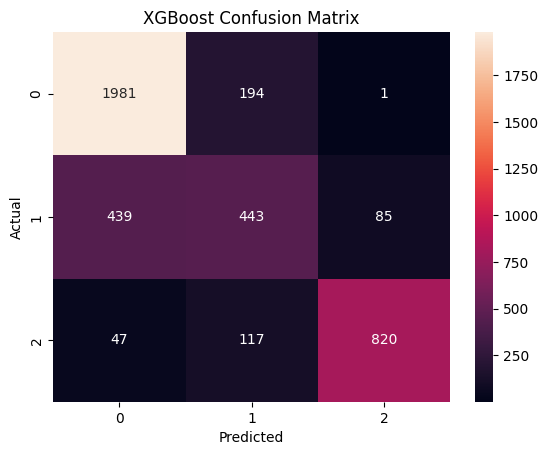

In [ ]:
# If not installed, run once:
# !pip install xgboost

from xgboost import XGBClassifier

# Train model
xgb = XGBClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=5,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric='mlogloss',
    random_state=42
)

xgb.fit(X_train, y_train)

# Predictions
y_pred_xgb = xgb.predict(X_test)

# Accuracy
print("XGBoost Accuracy:", accuracy_score(y_test, y_pred_xgb))

# Classification Report
print("\nClassification Report:\n", classification_report(y_test, y_pred_xgb))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred_xgb)

plt.figure()
sns.heatmap(cm, annot=True, fmt='d')
plt.title("XGBoost Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [ ]:
import numpy as np
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense

# Reshape for LSTM
X_lstm = X_scaled.reshape((X_scaled.shape[0], 1, X_scaled.shape[1]))

# Split
X_train_lstm, X_test_lstm, y_train_lstm, y_test_lstm = train_test_split(
    X_lstm, y_class, test_size=0.2, random_state=42
)

# Build model
model = Sequential()
model.add(LSTM(50, input_shape=(1, X_scaled.shape[1])))
model.add(Dense(3, activation='softmax'))

model.compile(loss='sparse_categorical_crossentropy',
              optimizer='adam',
              metrics=['accuracy'])

# Train
model.fit(X_train_lstm, y_train_lstm, epochs=5, batch_size=32)

# Evaluate
loss, acc = model.evaluate(X_test_lstm, y_test_lstm)
print("LSTM Accuracy:", acc)

Epoch 1/5
516/516 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.7434 - loss: 0.5960
Epoch 2/5
516/516 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.7834 - loss: 0.4958
Epoch 3/5
516/516 ━━━━━━━━━━━━━━━━━━━━ 6s 11ms/step - accuracy: 0.7881 - loss: 0.4850
Epoch 4/5
516/516 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - accuracy: 0.7884 - loss: 0.4801
Epoch 5/5
516/516 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.7901 - loss: 0.4768
129/129 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7882 - loss: 0.4919
LSTM Accuracy: 0.7882238626480103


In [ ]:
# Get probabilities
y_prob_lstm = model.predict(X_test_lstm)

# Convert to class labels
import numpy as np
y_pred_lstm = np.argmax(y_prob_lstm, axis=1)

129/129 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


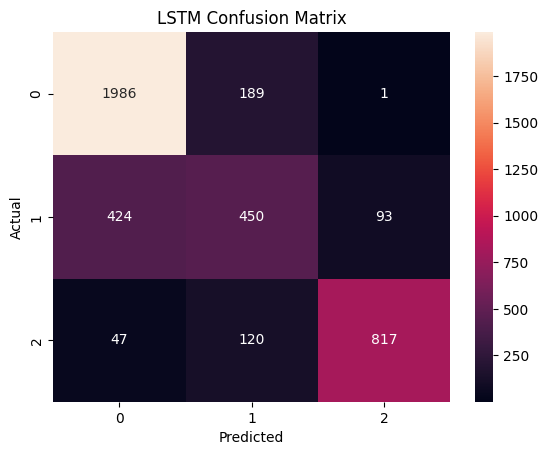


LSTM Classification Report:
               precision    recall  f1-score   support

           0       0.81      0.91      0.86      2176
           1       0.59      0.47      0.52       967
           2       0.90      0.83      0.86       984

    accuracy                           0.79      4127
   macro avg       0.77      0.74      0.75      4127
weighted avg       0.78      0.79      0.78      4127



In [ ]:
from sklearn.metrics import confusion_matrix, classification_report

cm = confusion_matrix(y_test_lstm, y_pred_lstm)

import seaborn as sns
import matplotlib.pyplot as plt

plt.figure()
sns.heatmap(cm, annot=True, fmt='d')
plt.title("LSTM Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

print("\nLSTM Classification Report:\n", classification_report(y_test_lstm, y_pred_lstm))

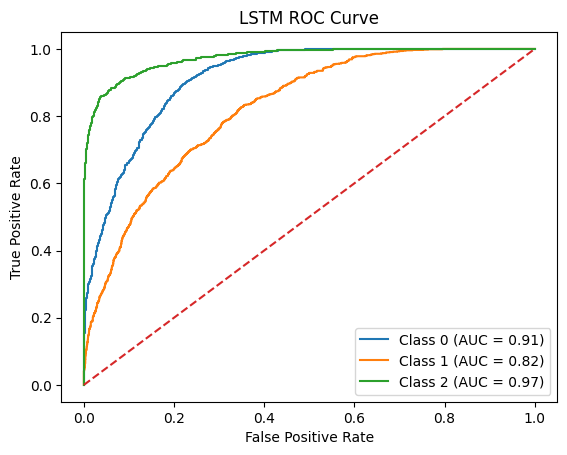

In [ ]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc

# Binarize labels
y_test_bin_lstm = label_binarize(y_test_lstm, classes=[0,1,2])
n_classes = y_test_bin_lstm.shape[1]

plt.figure()

for i in range(n_classes):
    fpr, tpr, _ = roc_curve(y_test_bin_lstm[:, i], y_prob_lstm[:, i])
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f"Class {i} (AUC = {roc_auc:.2f})")

plt.plot([0,1], [0,1], linestyle='--')
plt.title("LSTM ROC Curve")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.show()

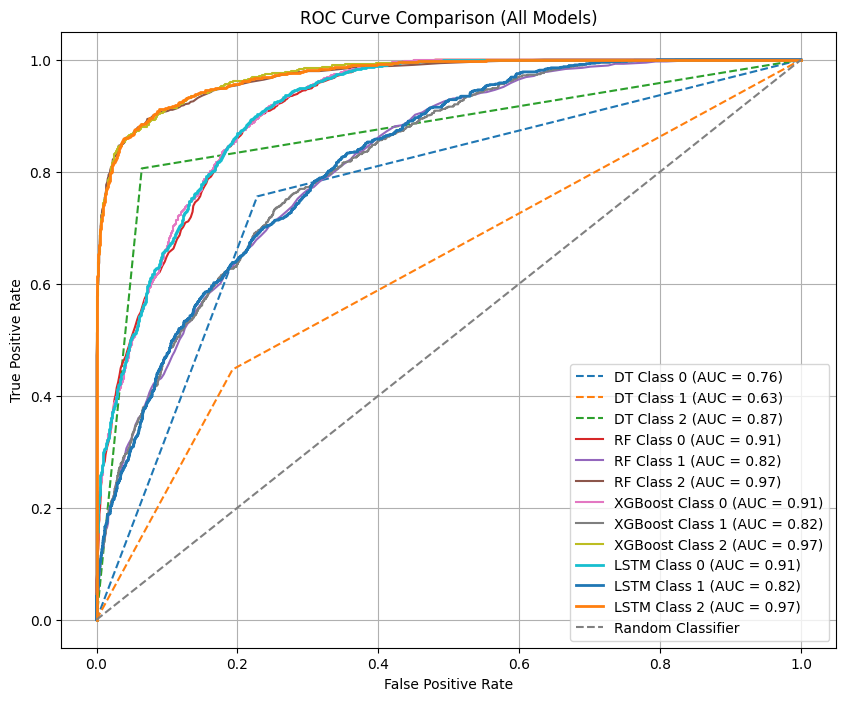

In [ ]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc

plt.figure(figsize=(10, 8))

# Binarize labels for all models (using y_test, which is common for DT, RF, XGB)
y_test_bin = label_binarize(y_test, classes=[0,1,2])

# Get probability predictions for each model
y_prob_dt = dt.predict_proba(X_test)
y_prob_rf = rf.predict_proba(X_test)
y_prob_xgb = xgb.predict_proba(X_test)


# Decision Tree
for i in range(n_classes):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_prob_dt[:, i])
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, linestyle='--', label=f"DT Class {i} (AUC = {roc_auc:.2f})")

# Random Forest
for i in range(n_classes):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_prob_rf[:, i])
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f"RF Class {i} (AUC = {roc_auc:.2f})")

# XGBoost
for i in range(n_classes):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_prob_xgb[:, i])
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f"XGBoost Class {i} (AUC = {roc_auc:.2f})")

# LSTM
for i in range(n_classes):
    fpr, tpr, _ = roc_curve(y_test_bin_lstm[:, i], y_prob_lstm[:, i])
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, linewidth=2, label=f"LSTM Class {i} (AUC = {roc_auc:.2f})")

plt.plot([0,1], [0,1], linestyle='--', color='gray', label='Random Classifier')
plt.title("ROC Curve Comparison (All Models)")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score

models = ['DT', 'RF', 'XGB', 'LSTM']

precision = [
    precision_score(y_test, y_pred_dt, average='weighted'),
    precision_score(y_test, y_pred_rf, average='weighted'),
    precision_score(y_test, y_pred_xgb, average='weighted'),
    precision_score(y_test_lstm, y_pred_lstm, average='weighted')
]

recall = [
    recall_score(y_test, y_pred_dt, average='weighted'),
    recall_score(y_test, y_pred_rf, average='weighted'),
    recall_score(y_test, y_pred_xgb, average='weighted'),
    recall_score(y_test_lstm, y_pred_lstm, average='weighted')
]

f1 = [
    f1_score(y_test, y_pred_dt, average='weighted'),
    f1_score(y_test, y_pred_rf, average='weighted'),
    f1_score(y_test, y_pred_xgb, average='weighted'),
    f1_score(y_test_lstm, y_pred_lstm, average='weighted')
]

print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)

Precision: [0.7021633416865583, 0.7785450367081628, 0.7768518795205517, 0.778932562871789]
Recall: [0.6954204022292222, 0.7879815846862127, 0.7860431306033439, 0.7882238914465713]
F1 Score: [0.6984800107965679, 0.7783127024166041, 0.7774436909330156, 0.7798031718816532]


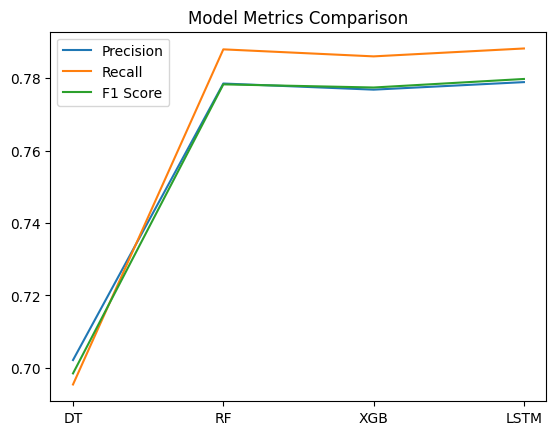

In [ ]:
import numpy as np

x = np.arange(len(models))

plt.figure()
plt.plot(x, precision, label='Precision')
plt.plot(x, recall, label='Recall')
plt.plot(x, f1, label='F1 Score')

plt.xticks(x, models)
plt.title("Model Metrics Comparison")
plt.legend()
plt.show()

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

models = ['Decision Tree', 'Random Forest', 'XGBoost', 'LSTM']

accuracy = [
    accuracy_score(y_test, y_pred_dt),
    accuracy_score(y_test, y_pred_rf),
    accuracy_score(y_test, y_pred_xgb),
    acc
]

precision = [
    precision_score(y_test, y_pred_dt, average='weighted'),
    precision_score(y_test, y_pred_rf, average='weighted'),
    precision_score(y_test, y_pred_xgb, average='weighted'),
    precision_score(y_test_lstm, y_pred_lstm, average='weighted')
]

recall = [
    recall_score(y_test, y_pred_dt, average='weighted'),
    recall_score(y_test, y_pred_rf, average='weighted'),
    recall_score(y_test, y_pred_xgb, average='weighted'),
    recall_score(y_test_lstm, y_pred_lstm, average='weighted')
]

f1 = [
    f1_score(y_test, y_pred_dt, average='weighted'),
    f1_score(y_test, y_pred_rf, average='weighted'),
    f1_score(y_test, y_pred_xgb, average='weighted'),
    f1_score(y_test_lstm, y_pred_lstm, average='weighted')
]

In [ ]:
import pandas as pd

results = pd.DataFrame({
    'Model': models,
    'Accuracy': accuracy,
    'Precision': precision,
    'Recall': recall,
    'F1 Score': f1
})

print(results)

           Model  Accuracy  Precision    Recall  F1 Score
0  Decision Tree  0.695420   0.702163  0.695420  0.698480
1  Random Forest  0.787982   0.778545  0.787982  0.778313
2        XGBoost  0.786043   0.776852  0.786043  0.777444
3           LSTM  0.788224   0.778933  0.788224  0.779803


In [ ]:
best_model = results.loc[results['F1 Score'].idxmax()]

print("Best Model:")
print(best_model)

Best Model:
Model            LSTM
Accuracy     0.788224
Precision    0.778933
Recall       0.788224
F1 Score     0.779803
Name: 3, dtype: object


In [ ]:
# ======================
# TEST DATA EVALUATION
# ======================

# Load test dataset
test_df = pd.read_csv('/content/test_FD001.txt', sep=" ", header=None)
test_df = test_df.dropna(axis=1)

# Assign initial column names
test_df.columns = columns

# Drop the same low-variance columns as in training
drop_cols = ['sensor_1','sensor_5','sensor_6','sensor_10','sensor_16','sensor_18','sensor_19']
test_df = test_df.drop(columns=drop_cols)

# Load RUL file
rul_df = pd.read_csv('/content/RUL_FD001.txt', header=None)
rul_df.columns = ['RUL']

In [ ]:
# Get last cycle for each engine
test_max_cycle = test_df.groupby('engine_id')['cycle'].max().reset_index()
test_max_cycle.columns = ['engine_id', 'max_cycle']

# Add RUL values from file
test_max_cycle['RUL'] = rul_df['RUL']

# Merge with test data
test_df = test_df.merge(test_max_cycle, on='engine_id')

In [ ]:
test_df['RUL'] = test_df['RUL'] + test_df['max_cycle'] - test_df['cycle']

In [ ]:
# Drop same columns used in training
test_df = test_df.drop(columns=['engine_id', 'cycle', 'max_cycle'])

# Separate features and target
X_test_real = test_df.drop(columns=['RUL'])
y_test_real = test_df['RUL']

# Apply SAME scaler
X_test_real = scaler.transform(X_test_real)

In [ ]:
y_test_class = y_test_real.apply(classify_rul)

In [ ]:
import numpy as np

X_test_lstm_real = X_test_real.reshape((X_test_real.shape[0], 1, X_test_real.shape[1]))

y_prob_real = model.predict(X_test_lstm_real)
y_pred_real = np.argmax(y_prob_real, axis=1)

410/410 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


In [ ]:
from sklearn.metrics import accuracy_score, classification_report

print("Final Test Accuracy:", accuracy_score(y_test_class, y_pred_real))
print(classification_report(y_test_class, y_pred_real))

Final Test Accuracy: 0.8347587049480758
              precision    recall  f1-score   support

           0       0.87      0.96      0.91      9902
           1       0.58      0.38      0.46      2308
           2       0.80      0.64      0.71       886

    accuracy                           0.83     13096
   macro avg       0.75      0.66      0.70     13096
weighted avg       0.82      0.83      0.82     13096



In [ ]:
import pandas as pd
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

results = []

for name, model in models.items():
    y_pred = model.predict(X_test)

    results.append([
        name,
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred, average='weighted'),
        recall_score(y_test, y_pred, average='weighted'),
        f1_score(y_test, y_pred, average='weighted')
    ])

# Create clean table with column names
summary_df = pd.DataFrame(results, columns=[
    "Model Name",
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score"
])

# Sort by highest accuracy
summary_df = summary_df.sort_values(by="Accuracy", ascending=False)

# Print as proper table
print("\n================ MODEL PERFORMANCE SUMMARY ================\n")
print(summary_df.to_string(index=False))
print("\n===========================================================")

In [ ]:
import time
import numpy as np

print("Starting Digital Twin Simulation...\n")

# Mix of all conditions
sample_df = test_df.sample(50).sort_values(by='RUL', ascending=False)

for i in range(len(sample_df)):

    sample = sample_df.iloc[i:i+1]

    X_sample = sample.drop(columns=['RUL'])
    X_sample_scaled = scaler.transform(X_sample)

    X_sample_lstm = X_sample_scaled.reshape((1, 1, X_sample_scaled.shape[1]))

    y_prob = model.predict(X_sample_lstm, verbose=0)
    pred = np.argmax(y_prob, axis=1)[0]

    status_map = {0: "Healthy", 1: "Warning", 2: "Critical"}
    status = status_map[pred]

    actual_rul = sample['RUL'].values[0]

    print(f"RUL: {actual_rul} → Predicted: {status}")

    time.sleep(0.5)

print("\nDigital Twin Simulation Completed.")

Starting Digital Twin Simulation...

RUL: 249 → Predicted: Healthy
RUL: 243 → Predicted: Healthy
RUL: 240 → Predicted: Healthy
RUL: 219 → Predicted: Healthy
RUL: 215 → Predicted: Healthy
RUL: 208 → Predicted: Healthy
RUL: 206 → Predicted: Healthy
RUL: 199 → Predicted: Healthy
RUL: 196 → Predicted: Healthy
RUL: 194 → Predicted: Healthy
RUL: 192 → Predicted: Healthy
RUL: 173 → Predicted: Healthy
RUL: 171 → Predicted: Healthy
RUL: 169 → Predicted: Healthy
RUL: 160 → Predicted: Healthy
RUL: 159 → Predicted: Healthy
RUL: 143 → Predicted: Healthy
RUL: 140 → Predicted: Healthy
RUL: 137 → Predicted: Healthy
RUL: 131 → Predicted: Healthy
RUL: 130 → Predicted: Healthy
RUL: 127 → Predicted: Healthy
RUL: 121 → Predicted: Healthy
RUL: 120 → Predicted: Healthy
RUL: 119 → Predicted: Healthy
RUL: 115 → Predicted: Healthy
RUL: 115 → Predicted: Healthy
RUL: 113 → Predicted: Warning
RUL: 112 → Predicted: Healthy
RUL: 111 → Predicted: Healthy
RUL: 102 → Predicted: Warning
RUL: 98 → Predicted: Healthy
RUL:

In [ ]:
print(np.unique(y_train, return_counts=True))

(array([0, 1, 2]), array([8355, 4033, 4116]))


In [ ]:
def label_rul(rul):
    if rul > 60:
        return 0  # Healthy
    elif rul > 30:
        return 1  # Warning
    else:
        return 2  # Critical

In [ ]:
import time
import numpy as np
import pandas as pd # Ensure pandas is imported for DataFrame operations

print("\n🚀 Starting Real-Time Engine Health Simulation...\n")

status_map = {0: "🟢 Healthy", 1: "🟡 Warning", 2: "🔴 Critical"}

# Get a random engine as the initial state for the simulation
engine_initial_features = test_df.sample(1).iloc[0:1].drop(columns=['RUL']).copy()

# This DataFrame will hold the engine's current features, which will degrade cumulatively
current_engine_state = engine_initial_features.copy()

# Identify sensor columns for targeted degradation
sensor_cols_names = [col for col in current_engine_state.columns if 'sensor_' in col]
sensor_cols_indices = [current_engine_state.columns.get_loc(col) for col in sensor_cols_names]

for t in range(30):

    # Initialize a degradation array for all features, mostly zeros
    base_degradation_array = np.zeros(current_engine_state.shape)

    if t < 10:
        # Healthy phase: very small degradation per step for sensors
        degradation_for_sensors = np.random.normal(0.005, 0.001, size=(1, len(sensor_cols_names))) # Significantly reduced degradation
    elif t < 20:
        # Warning phase: moderate degradation per step for sensors
        degradation_for_sensors = np.random.normal(0.02, 0.005, size=(1, len(sensor_cols_names))) # Significantly reduced degradation
    else:
        # Critical phase: heavy degradation per step for sensors
        degradation_for_sensors = np.random.normal(0.05, 0.01, size=(1, len(sensor_cols_names))) # Significantly reduced degradation

        # Add random spikes to a few sensors for critical phase
        spike_indices_in_sensor_array = np.random.choice(len(sensor_cols_names), size=3, replace=False)
        # Fix: Generate a 1D array of size 3 to match the selected slice
        degradation_for_sensors[0, spike_indices_in_sensor_array] += np.random.uniform(0.1, 0.5, size=3) # Significantly reduced spike values

    # Apply the generated degradation values to the corresponding sensor columns in the full degradation array
    for i, sensor_idx in enumerate(sensor_cols_indices):
        base_degradation_array[0, sensor_idx] = degradation_for_sensors[0, i]

    # Apply cumulative degradation to the current engine state
    current_engine_state = current_engine_state + base_degradation_array

    # Scale the current degraded state for prediction
    X_scaled_sample = scaler.transform(current_engine_state)

    # Reshape for LSTM model (expecting 3D input: (samples, timesteps, features))
    X_lstm_sample = X_scaled_sample.reshape((1, 1, X_scaled_sample.shape[1]))

    # Predict the health status using the LSTM model
    y_prob = model.predict(X_lstm_sample, verbose=0)
    pred = np.argmax(y_prob, axis=1)[0]
    confidence = np.max(y_prob)

    # Print simulated output for the current time step
    print(f"Time Step: {t+1}")
    print(f"Predicted Status: {status_map[pred]}")
    print(f"Confidence: {confidence:.2f}")
    print("-" * 40)

    time.sleep(0.5)

print("\n✅ Simulation Completed.")


🚀 Starting Real-Time Engine Health Simulation...

Time Step: 1
Predicted Status: 🟢 Healthy
Confidence: 0.88
----------------------------------------
Time Step: 2
Predicted Status: 🟢 Healthy
Confidence: 0.87
----------------------------------------
Time Step: 3
Predicted Status: 🟢 Healthy
Confidence: 0.86
----------------------------------------
Time Step: 4
Predicted Status: 🟢 Healthy
Confidence: 0.86
----------------------------------------
Time Step: 5
Predicted Status: 🟢 Healthy
Confidence: 0.85
----------------------------------------
Time Step: 6
Predicted Status: 🟢 Healthy
Confidence: 0.85
----------------------------------------
Time Step: 7
Predicted Status: 🟢 Healthy
Confidence: 0.84
----------------------------------------
Time Step: 8
Predicted Status: 🟢 Healthy
Confidence: 0.84
----------------------------------------
Time Step: 9
Predicted Status: 🟢 Healthy
Confidence: 0.83
----------------------------------------
Time Step: 10
Predicted Status: 🟢 Healthy
Confidence: 0.83

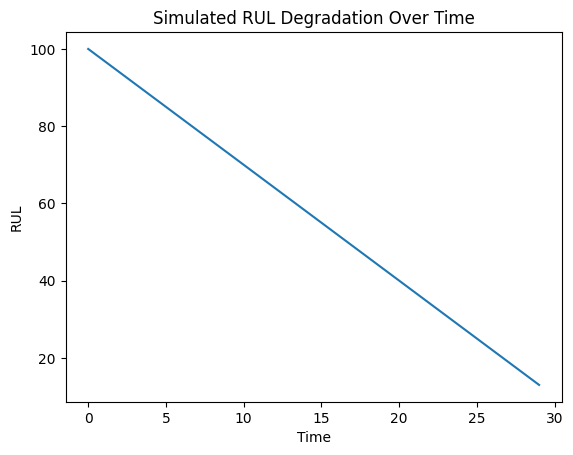

In [ ]:
import matplotlib.pyplot as plt

rul_trend = []

for t in range(30):
    rul_trend.append(100 - t*3)  # fake degradation

plt.plot(rul_trend)
plt.title("Simulated RUL Degradation Over Time")
plt.xlabel("Time")
plt.ylabel("RUL")
plt.show()

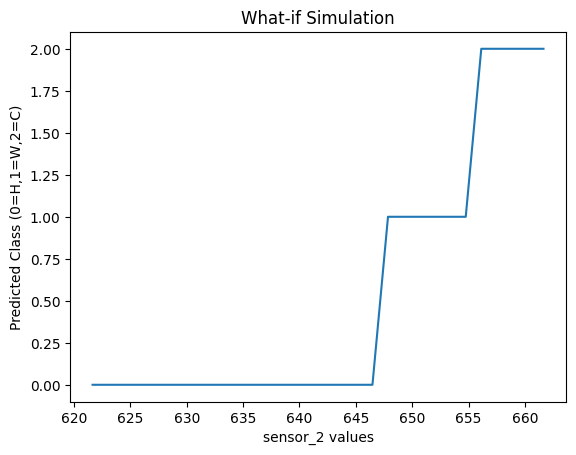

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# take one sample
base_sample = test_df.sample(1).drop(columns=['RUL']).copy()

sensor_name = 'sensor_2'   # change this

values = np.linspace(
    base_sample[sensor_name].values[0] - 20,
    base_sample[sensor_name].values[0] + 20,
    30
)

pred_classes = []

for v in values:
    temp = base_sample.copy()
    temp[sensor_name] = v

    X_scaled = scaler.transform(temp)
    X_lstm = X_scaled.reshape((1, 1, X_scaled.shape[1]))

    y_prob = model.predict(X_lstm, verbose=0)
    pred = np.argmax(y_prob)

    pred_classes.append(pred)

# plot
plt.plot(values, pred_classes)
plt.xlabel(f"{sensor_name} values")
plt.ylabel("Predicted Class (0=H,1=W,2=C)")
plt.title("What-if Simulation")
plt.show()

In [ ]:
base_sample = test_df.sample(1).drop(columns=['RUL']).copy()

results = []

for temp_increase in range(0, 40, 5):
    for vib_increase in range(0, 30, 5):

        temp_sample = base_sample.copy()

        temp_sample['sensor_2'] += temp_increase
        # Changed 'sensor_5' to 'sensor_7' as 'sensor_5' was dropped earlier
        temp_sample['sensor_7'] += vib_increase

        X_scaled = scaler.transform(temp_sample)
        X_lstm = X_scaled.reshape((1, 1, X_scaled.shape[1]))

        y_prob = model.predict(X_lstm, verbose=0)
        pred = np.argmax(y_prob)

        results.append((temp_increase, vib_increase, pred))

# print some results
for r in results[:10]:
    print(f"Temp+{r[0]}, Vib+{r[1]} \u2192 Class {r[2]}")

Temp+0, Vib+0 → Class 2
Temp+0, Vib+5 → Class 2
Temp+0, Vib+10 → Class 1
Temp+0, Vib+15 → Class 0
Temp+0, Vib+20 → Class 0
Temp+0, Vib+25 → Class 0
Temp+5, Vib+0 → Class 2
Temp+5, Vib+5 → Class 2
Temp+5, Vib+10 → Class 1
Temp+5, Vib+15 → Class 0


In [ ]:
sensor_cols = [col for col in test_df.columns if 'sensor_' in col]

base_sample = test_df.sample(1).drop(columns=['RUL']).copy()

impact_scores = {}

for sensor in sensor_cols:

    temp = base_sample.copy()

    original_value = temp[sensor].values[0]
    temp[sensor] = original_value + 20   # small change

    X_scaled = scaler.transform(temp)
    X_lstm = X_scaled.reshape((1, 1, X_scaled.shape[1]))

    y_prob = model.predict(X_lstm, verbose=0)
    impact_scores[sensor] = np.max(y_prob)

# sort by impact
sorted_impact = sorted(impact_scores.items(), key=lambda x: x[1], reverse=True)

print("\n🔍 Sensor Impact Ranking:")
for s in sorted_impact[:10]:
    print(s)


🔍 Sensor Impact Ranking:
('sensor_11', np.float32(0.9883916))
('sensor_2', np.float32(0.8369037))
('sensor_13', np.float32(0.74164367))
('sensor_20', np.float32(0.7371326))
('sensor_12', np.float32(0.6982203))
('sensor_15', np.float32(0.67203426))
('sensor_3', np.float32(0.65215373))
('sensor_7', np.float32(0.64405286))
('sensor_9', np.float32(0.6160436))
('sensor_14', np.float32(0.6122957))


In [ ]:
import time
import numpy as np

print("Starting Simulation...\n")

# Step 1: Take sample data
sample_df = test_df.sample(50)

# Step 2: Loop (time simulation)
for i in range(len(sample_df)):

    # Step 3: Get one data point
    sample = sample_df.iloc[i:i+1]

    # Step 4: Preprocess
    X = sample.drop(columns=['RUL'])
    X_scaled = scaler.transform(X)
    X_lstm = X_scaled.reshape((1, 1, X_scaled.shape[1]))

    # Step 5: Predict
    y_prob = model.predict(X_lstm, verbose=0)
    pred = np.argmax(y_prob, axis=1)[0]

    # Step 6: Convert to label
    if pred == 0:
        status = "Healthy"
    elif pred == 1:
        status = "Warning"
    else:
        status = "Critical"

    # Step 7: Display output
    print(f"Step {i+1}: Predicted = {status}")

    # Step 8: Delay (simulation effect)
    time.sleep(0.5)

print("\nSimulation Completed.")

Starting Simulation...

Step 1: Predicted = Healthy
Step 2: Predicted = Warning
Step 3: Predicted = Healthy
Step 4: Predicted = Warning
Step 5: Predicted = Healthy
Step 6: Predicted = Healthy
Step 7: Predicted = Healthy
Step 8: Predicted = Healthy
Step 9: Predicted = Healthy
Step 10: Predicted = Healthy
Step 11: Predicted = Healthy
Step 12: Predicted = Critical
Step 13: Predicted = Healthy
Step 14: Predicted = Warning
Step 15: Predicted = Healthy
Step 16: Predicted = Healthy
Step 17: Predicted = Healthy
Step 18: Predicted = Healthy
Step 19: Predicted = Healthy
Step 20: Predicted = Healthy
Step 21: Predicted = Critical
Step 22: Predicted = Healthy
Step 23: Predicted = Healthy
Step 24: Predicted = Healthy
Step 25: Predicted = Healthy
Step 26: Predicted = Healthy
Step 27: Predicted = Healthy
Step 28: Predicted = Healthy
Step 29: Predicted = Healthy
Step 30: Predicted = Critical
Step 31: Predicted = Warning
Step 32: Predicted = Healthy
Step 33: Predicted = Healthy
Step 34: Predicted = Heal

In [ ]:
import time
import numpy as np

print("Starting One-Factor Digital Twin Simulation...\n")

# Take one base sample
base_sample = test_df.sample(1)

# Choose one factor (sensor)
factor = 'sensor_2'

# Simulate changes in that factor
for change in range(-15, 16, 5):

    simulated_sample = base_sample.copy()

    # stimulate one factor
    simulated_sample[factor] = simulated_sample[factor] + change

    # preprocess
    X = simulated_sample.drop(columns=['RUL'])
    X_scaled = scaler.transform(X)
    X_lstm = X_scaled.reshape((1, 1, X_scaled.shape[1]))

    # prediction
    y_prob = model.predict(X_lstm, verbose=0)
    pred = np.argmax(y_prob, axis=1)[0]

    # label
    if pred == 0:
        status = "Healthy"
    elif pred == 1:
        status = "Warning"
    else:
        status = "Critical"

    print(f"{factor} changed by {change:+} → Predicted = {status}")

    time.sleep(0.5)

print("\nOne-Factor Simulation Completed.")

Starting One-Factor Digital Twin Simulation...

sensor_2 changed by -15 → Predicted = Healthy
sensor_2 changed by -10 → Predicted = Healthy
sensor_2 changed by -5 → Predicted = Healthy
sensor_2 changed by +0 → Predicted = Healthy
sensor_2 changed by +5 → Predicted = Healthy
sensor_2 changed by +10 → Predicted = Warning
sensor_2 changed by +15 → Predicted = Warning

One-Factor Simulation Completed.


In [ ]:
import time
import numpy as np

print("Critical Zone Factor Simulation...\n")

# pick sample close to failure
base_sample = test_df[test_df['RUL'] < 60].sample(1)

factor = 'sensor_2'

for change in range(-50, 51, 10):

    simulated_sample = base_sample.copy()

    simulated_sample[factor] += change

    X = simulated_sample.drop(columns=['RUL'])
    X_scaled = scaler.transform(X)
    X_lstm = X_scaled.reshape((1, 1, X_scaled.shape[1]))

    y_prob = model.predict(X_lstm, verbose=0)
    pred = np.argmax(y_prob, axis=1)[0]

    status = ["Healthy", "Warning", "Critical"][pred]

    print(f"{factor} change {change:+} → {status}")

    time.sleep(0.5)

Critical Zone Factor Simulation...

sensor_2 change -50 → Warning
sensor_2 change -40 → Warning
sensor_2 change -30 → Healthy
sensor_2 change -20 → Healthy
sensor_2 change -10 → Healthy
sensor_2 change +0 → Critical
sensor_2 change +10 → Critical
sensor_2 change +20 → Critical
sensor_2 change +30 → Critical
sensor_2 change +40 → Critical
sensor_2 change +50 → Critical


GitHub link

In [ ]:
https://github.com/lochana-charvi-g/Predictive-Analysis-/tree/main